## In this project we are going to analyse the global cancer dataset to anwer some questions

In [1]:
## Importing the needed dataset
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('global_cancer_patients_2015_2024.csv')
df.head(4)

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12


In [7]:
## Checking the shape of the dataset
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns")

The dataset has 50000 rows and 15 columns


In [3]:
for col in df.columns:
    print(col)

Patient_ID
Age
Gender
Country_Region
Year
Genetic_Risk
Air_Pollution
Alcohol_Use
Smoking
Obesity_Level
Cancer_Type
Cancer_Stage
Treatment_Cost_USD
Survival_Years
Target_Severity_Score


In [ ]:
## Checking the datatype
for key, value in df.dtypes.items():
    print(f"{key} ---------------> {value}")

Patient_ID ---------------> object
Age ---------------> int64
Gender ---------------> object
Country_Region ---------------> object
Year ---------------> int64
Genetic_Risk ---------------> float64
Air_Pollution ---------------> float64
Alcohol_Use ---------------> float64
Smoking ---------------> float64
Obesity_Level ---------------> float64
Cancer_Type ---------------> object
Cancer_Stage ---------------> object
Treatment_Cost_USD ---------------> float64
Survival_Years ---------------> float64
Target_Severity_Score ---------------> float64


In [6]:
### Finding the descriptive statistics of the dataset
df.describe()

,Age,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,54.421540,2019.480520,5.001698,5.010126,5.010880,4.989826,4.991176,52467.298239,5.006462,4.951207
std,20.224451,2.871485,2.885773,2.888399,2.888769,2.881579,2.894504,27363.229379,2.883335,1.199677
min,20.000000,2015.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5000.050000,0.000000,0.900000
25%,37.000000,2017.000000,2.500000,2.500000,2.500000,2.500000,2.500000,28686.225000,2.500000,4.120000
50%,54.000000,2019.000000,5.000000,5.000000,5.000000,5.000000,5.000000,52474.310000,5.000000,4.950000
75%,72.000000,2022.000000,7.500000,7.500000,7.500000,7.500000,7.500000,76232.720000,7.500000,5.780000
max,89.000000,2024.000000,10.000000,10.000000,10.000000,10.000000,10.000000,99999.840000,10.000000,9.160000


In [8]:
## Analysing some categorical variables
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk',
       'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level',
       'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='object')

In [ ]:
#The number of countries in the dataset
print('The data is for  %d countries' %(df['Country_Region'].nunique()))

The data is for  10 countries


In [10]:
for i in df['Country_Region'].unique():
    print(i)

UK
China
Pakistan
Brazil
Germany
Canada
USA
India
Australia
Russia


In [15]:
## How many cancer types
print('The dataset has %d cancer types' %(df['Cancer_Type'].nunique()))

The dataset has 8 cancer types


In [16]:
## The different cancer types
for i in df['Cancer_Type'].unique():
    print(i)

Lung
Leukemia
Breast
Colon
Skin
Cervical
Prostate
Liver


In [19]:
## Analysing how many cancer stages exist
print('Ther are %d cancer stages according to the dataset' %(df['Cancer_Stage'].nunique()))

Ther are 5 cancer stages according to the dataset


In [20]:
## Checking the different cancer stages
for i in df['Cancer_Stage'].unique():
    print(i)

Stage III
Stage 0
Stage II
Stage I
Stage IV


In [21]:
## Checking for missing values
for key, value in df.isna().sum().items():
    print(f'{key} ---------------------> {value}')

Patient_ID ---------------------> 0
Age ---------------------> 0
Gender ---------------------> 0
Country_Region ---------------------> 0
Year ---------------------> 0
Genetic_Risk ---------------------> 0
Air_Pollution ---------------------> 0
Alcohol_Use ---------------------> 0
Smoking ---------------------> 0
Obesity_Level ---------------------> 0
Cancer_Type ---------------------> 0
Cancer_Stage ---------------------> 0
Treatment_Cost_USD ---------------------> 0
Survival_Years ---------------------> 0
Target_Severity_Score ---------------------> 0


In [23]:
## Checking for duplicates
print('The dataset has %d duplicates' %(df.duplicated().sum()))


The dataset has 0 duplicates


#### START ANALYSIS

In [24]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk',
       'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level',
       'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='object')

### WHICH GENDER IS DEEPLY AFFECTED WITH THE CNACER

<Axes: xlabel='Gender'>

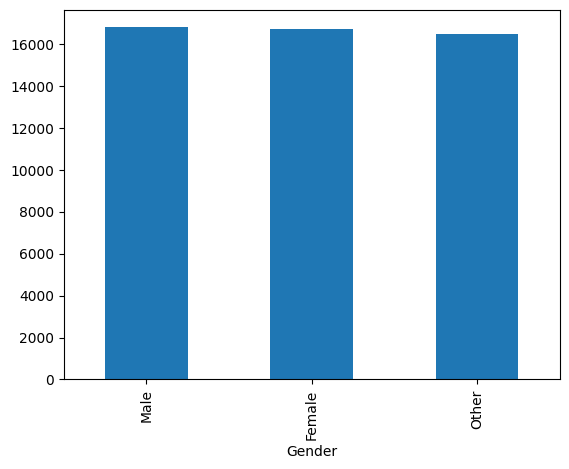

In [ ]:
## Which gender is affected most with the cancer using count and plot
df['Gender'].value_counts().plot(kind='bar')

In [33]:
## Using the groupby and aggregation function
df.groupby(['Gender'],as_index=1).agg({'Gender':'count'})

,Gender
Gender,
Female,16709
Male,16796
Other,16495


<Axes: xlabel='Gender', ylabel='count'>

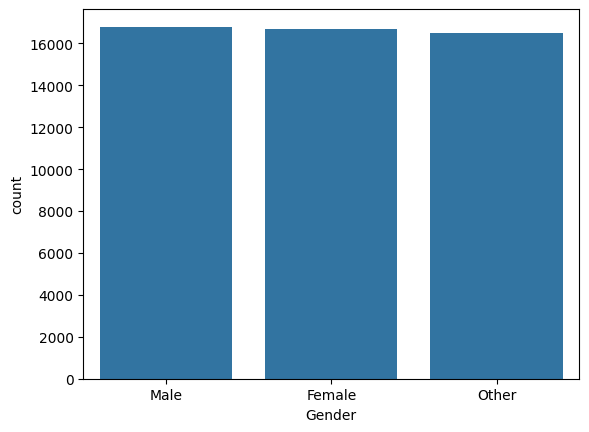

In [37]:
sns.countplot(data=df,x='Gender')

In [38]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk',
       'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level',
       'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='object')

<Axes: xlabel='Cancer_Stage'>

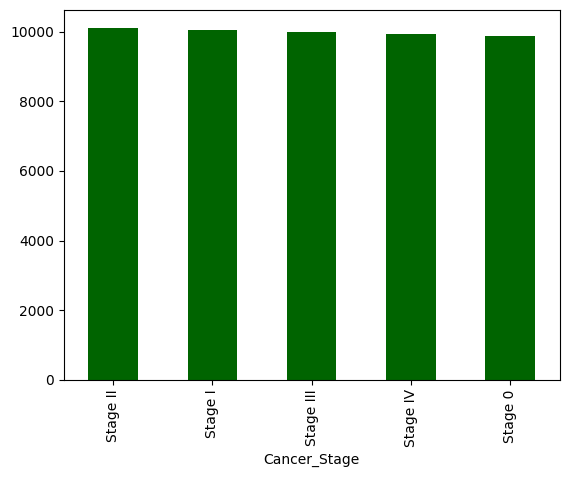

In [41]:
## Which cancer stage has the highest victims
df['Cancer_Stage'].value_counts().plot(kind='bar',color='darkgreen')

In [64]:
df.groupby(['Cancer_Stage']).agg({'Cancer_Stage':'count'})

,Cancer_Stage
Cancer_Stage,
Stage 0,9889
Stage I,10046
Stage II,10124
Stage III,10008
Stage IV,9933


In [55]:
## Check the distribution of numeric variables
def plot_box_plots(data):
    plt.figure(figsize=(20,20))
    for i,col in enumerate(data.select_dtypes(include=['int64','float64']).columns):
        plt.subplot(3,4, i+1)
        sns.boxplot(data = data[col],width=0.2,color='darkgreen')
        plt.title(col)
    plt.tight_layout()
    plt.show()

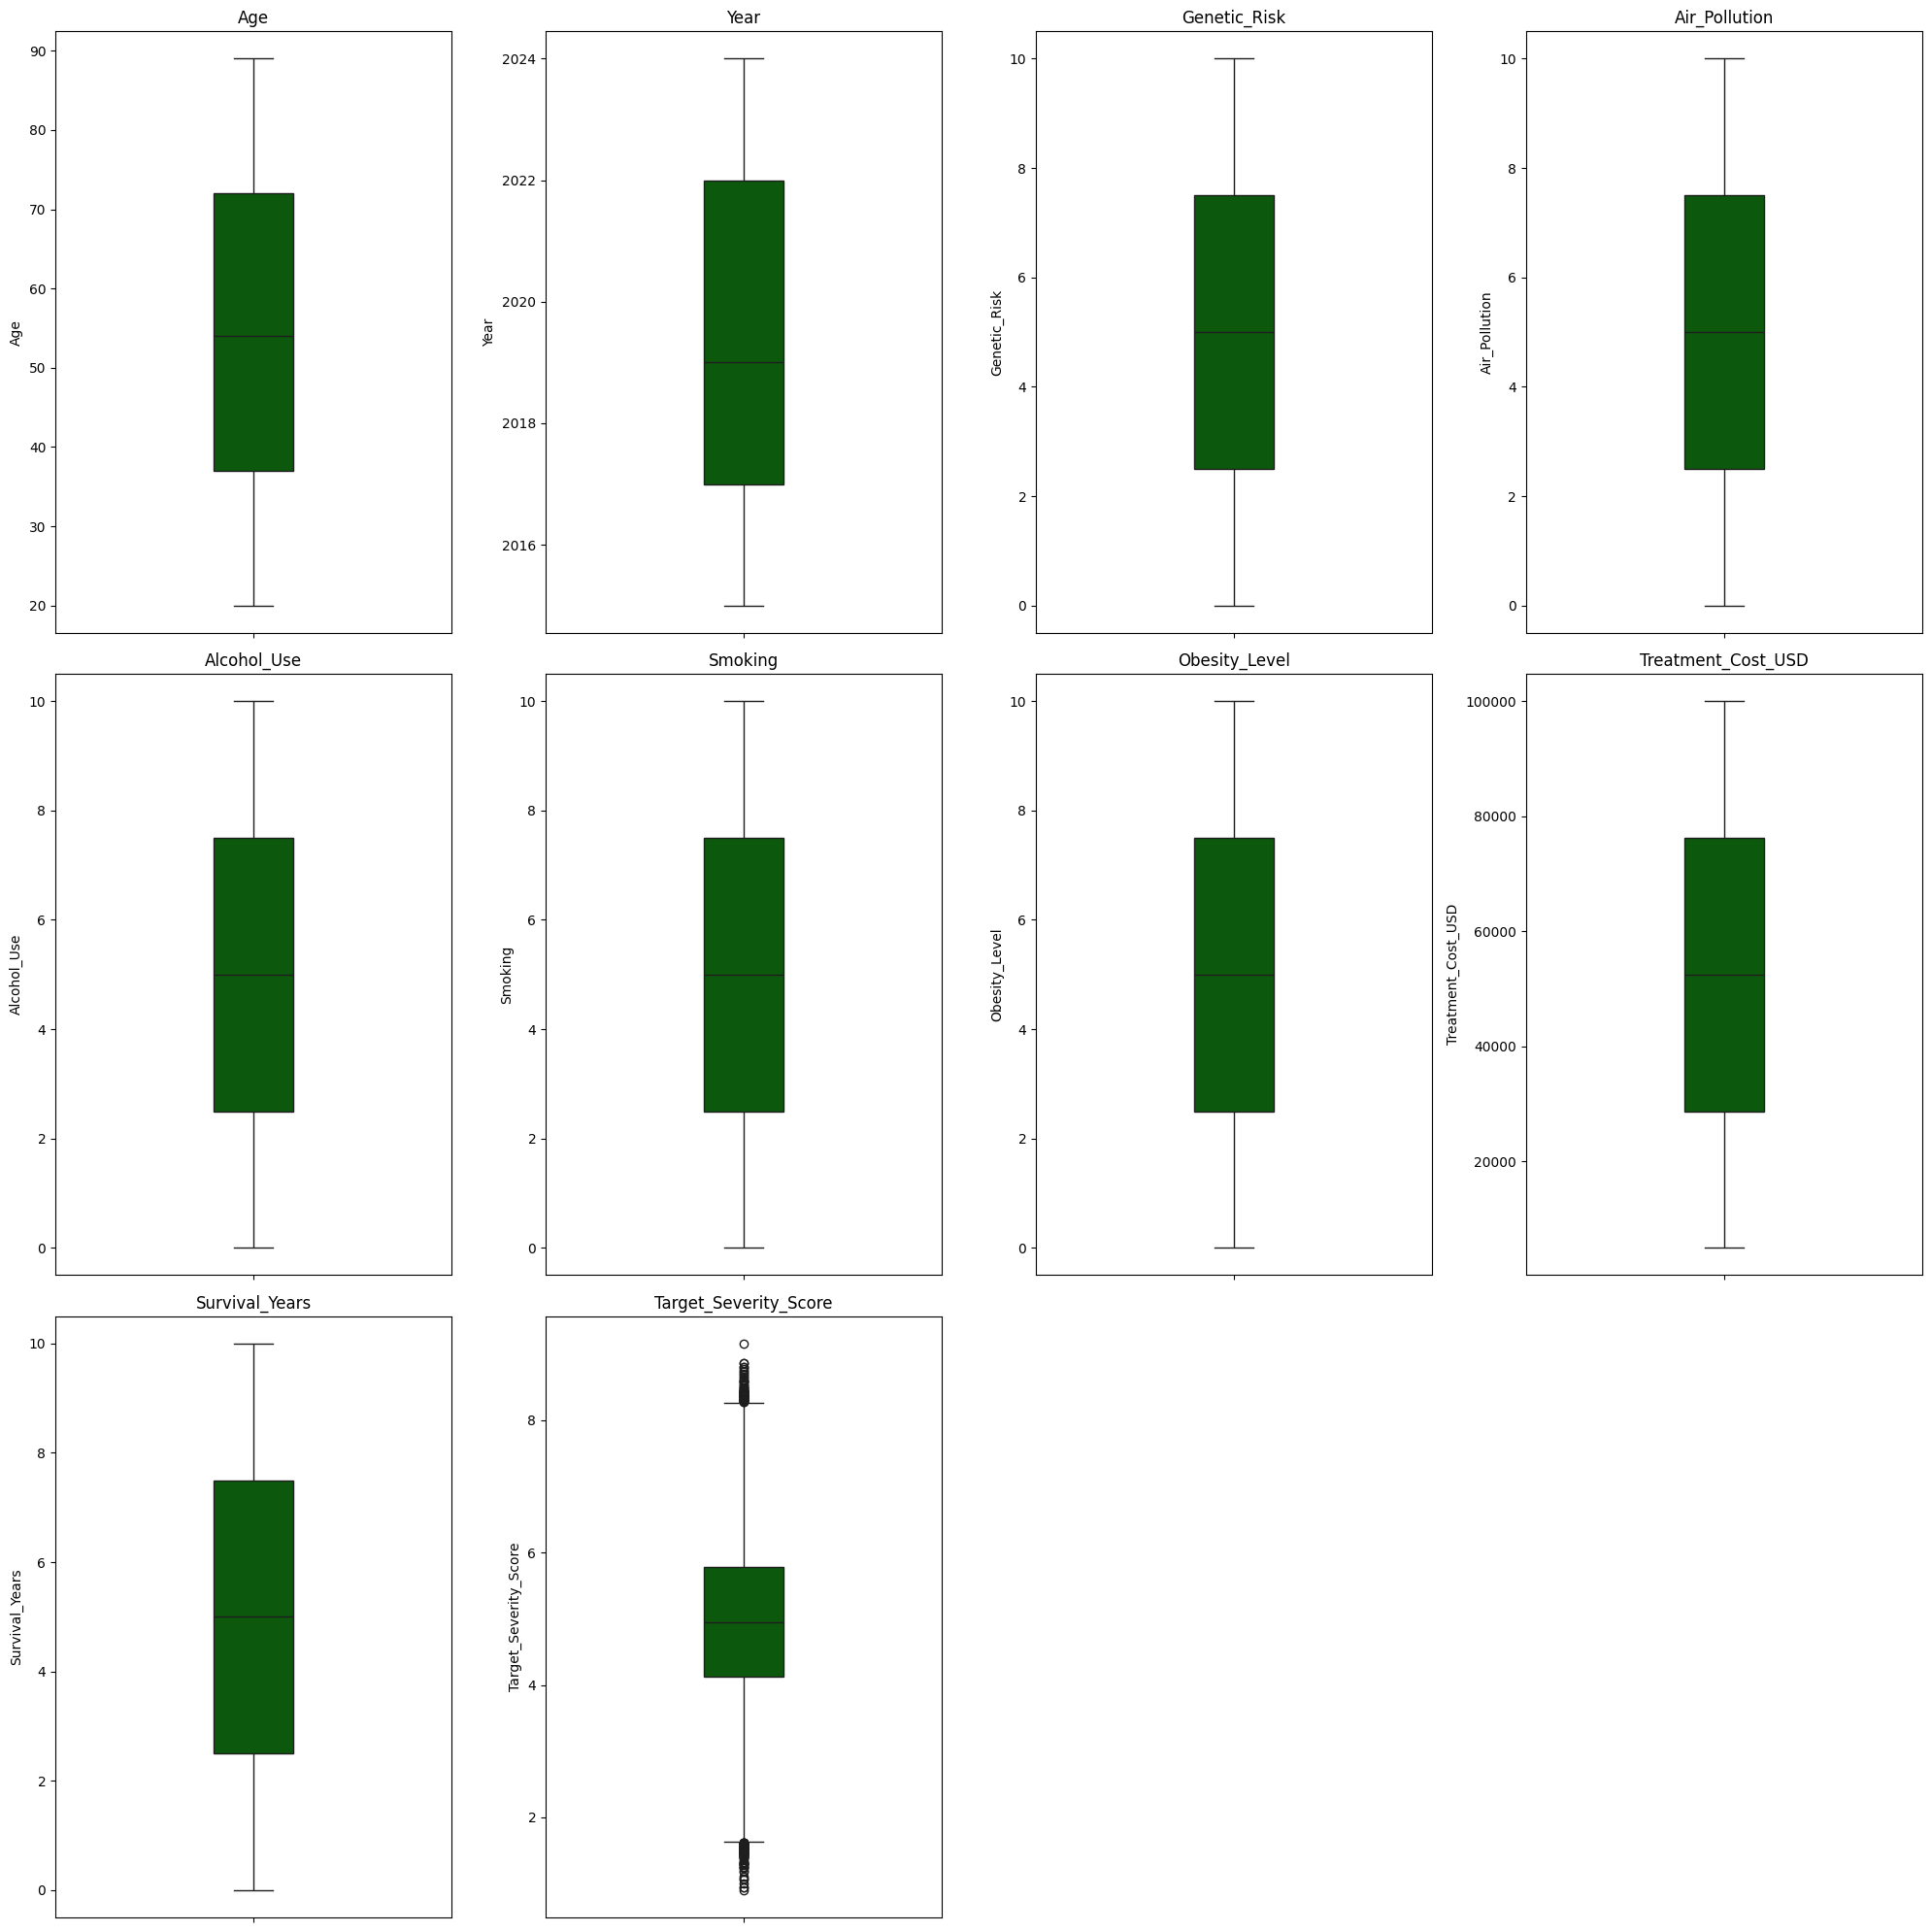

In [56]:
plot_box_plots(df)

#### Analysing the smoking rate the age and the servival rate of the cancer

In [58]:
df.head(4)

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12


In [59]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk',
       'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level',
       'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='object')

In [ ]:
## Cancer type by smoking rate
df.groupby(['Cancer_Type'],as_index=None).agg({'Smoking':'sum'})

,Cancer_Type,Smoking
0,Breast,31005.6
1,Cervical,30898.7
2,Colon,31476.8
3,Leukemia,31402.0
4,Liver,31574.8
5,Lung,30282.9
6,Prostate,31224.7
7,Skin,31625.8


<Axes: xlabel='Cancer_Type', ylabel='Smoking'>

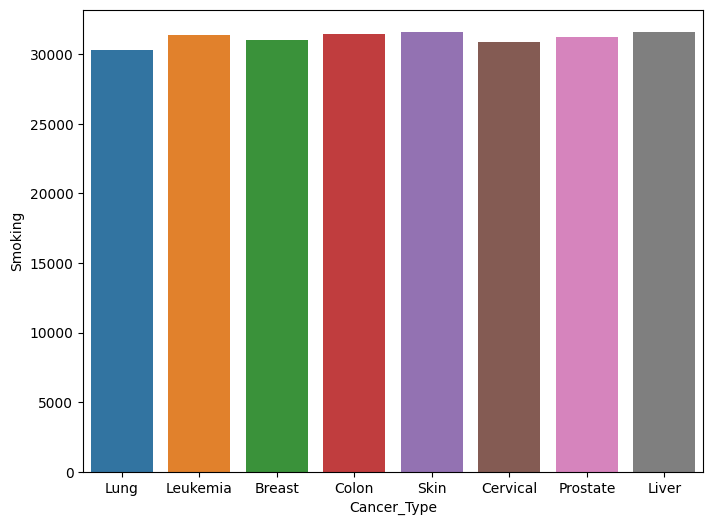

In [73]:
## Using a graph
plt.figure(figsize=(8,6))
sns.barplot(data=df,x='Cancer_Type',y='Smoking',hue='Cancer_Type',estimator='sum',errorbar=None)

In [74]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk',
       'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level',
       'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years',
       'Target_Severity_Score'],
      dtype='object')

In [76]:
## Air pollution by region
df.groupby(['Country_Region'],as_index=None).agg({'Air_Pollution':'sum'})

,Country_Region,Air_Pollution
0,Australia,25616.6
1,Brazil,25031.7
2,Canada,24234.1
3,China,24852.9
4,Germany,25022.4
5,India,25415.5
6,Pakistan,24708.3
7,Russia,25017.9
8,UK,25570.0
9,USA,25036.9
